In [17]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import matplotlib
from pathlib import Path
from pandas import DataFrame
from typing import List
import warnings
from io import StringIO
import sys

warnings.filterwarnings('ignore')
matplotlib.use('Agg')
%matplotlib inline

import HumSpectra.fluorescence as Hfl
import HumSpectra.ultraviolet as Huv
import HumSpectra.math_stat as Hst
import HumSpectra.geomodule as Hgeo
import HumSpectra.drawmodule as Hplt
wdir_results = Path.cwd().parent / "Received data" / "2024" / "Graphs"

In [ ]:
wdir = Path.cwd().parent / "Initial data" / "2024"


fluo_paths = Path.joinpath(wdir, "Fluorescence")
uv_paths = Path.joinpath(wdir, "UV")
fluo_spectra_list = [Hfl.read_fluo_3d(str(path)) for path in fluo_paths.rglob('*.csv')]
uv_spectra_list:List = [Huv.read_csv_uv(str(path),spectra_type="absorption") for path in uv_paths.rglob('*.csv')]

toc_data = pd.read_excel(Path.joinpath(wdir, 'C_org.xlsx')) # pyright: ignore[reportCallIssue]
map_data = pd.read_excel(Path.joinpath(wdir, 'Geodata.xlsx'))

fl_data = pd.DataFrame()

fl_data["Sample"] = [fl_spectra.attrs['name']
    for fl_spectra in fluo_spectra_list]

fl_data["Class"] = [fl_spectra.attrs['class']
    for fl_spectra in fluo_spectra_list]

fl_data["Subclass"] = [fl_spectra.attrs['subclass']
    for fl_spectra in fluo_spectra_list]

fl_data["Asm350"] = [Hfl.asm_350(fl_spectra)
    for fl_spectra in fluo_spectra_list]

fl_data["Asm280"] = [Hfl.asm_280(fl_spectra)
    for fl_spectra in fluo_spectra_list]

fl_data["FIX"] = [Hfl.fluo_index(fl_spectra)
    for fl_spectra in fluo_spectra_list]

fl_data["HIX"] = [Hfl.humin_index(fl_spectra)
    for fl_spectra in fluo_spectra_list]

fl_data = fl_data[fl_data.Class == "ADOM"]

uv_data = pd.DataFrame()

uv_data["Sample"] = [uv_spectra.attrs['name']
    for uv_spectra in uv_spectra_list]

uv_data["Class"] = [uv_spectra.attrs['class']
    for uv_spectra in uv_spectra_list]

uv_data["Subclass"] = [uv_spectra.attrs['subclass']
    for uv_spectra in uv_spectra_list]

uv_data["E2/E3"] = [Huv.e2_e3(uv_spectra)
    for uv_spectra in uv_spectra_list]

uv_data["E4/E6"] = [Huv.e4_e6(uv_spectra)
    for uv_spectra in uv_spectra_list]

uv_data["lambda"] = [Huv.lambda_UV(uv_spectra)
    for uv_spectra in uv_spectra_list]

uv_data["epsilon"] = [Huv.epsilon(uv_spectra)
    for uv_spectra in uv_spectra_list]

test = uv_data.copy()
uv_data = uv_data.merge(toc_data,on="Sample",how="inner")
uv_data = uv_data[uv_data.Class == "ADOM"]

uv_data["Suva"] = uv_data['epsilon']/uv_data['C_org']
uv_data.drop(columns=["epsilon"],inplace=True)

In [14]:
MainData = uv_data.merge(map_data[["Sample","pH","eH"]],on="Sample",how="inner").merge(fl_data, on=["Sample","Class","Subclass"],how="inner")
MainData.rename(columns={"E2/E3":"E2E3","E4/E6":"E4E6"},inplace=True)
MainData.drop_duplicates(inplace=True)
MainData.set_index(["Class","Subclass","Sample"],inplace=True)
feature_columns = ["E2E3","C_org","Suva","Asm350","Asm280"]
target_list = ["pH","eH"]
MainData = Hst.delete_eject_iqr(MainData,iqr_param=4,multi_index=True)
MainData

E2E3      E4E6    lambda  C_org      Suva  \
Class Subclass  Sample                                                       
ADOM  Storage 2 ADOM-SL2-10  3.615338  5.383128  0.048297  31.55  0.029540   
                ADOM-SL2-4   3.421265  5.218230  0.030559  16.21  0.026774   
                ADOM-SL2-5   3.449113  2.852366  0.027916  17.72  0.026168   
                ADOM-SL2-6   3.819086  3.892745  0.019282  13.71  0.026464   
                ADOM-SL2-8   3.847334  4.489124  0.013233  11.77  0.019912   
...                               ...       ...       ...    ...       ...   
      Storage 7 ADOM-SL7-5   5.399581  6.412753  0.005082  16.60  0.010066   
                ADOM-SL7-6   4.512113  5.413324  0.006876  15.60  0.009935   
                ADOM-SL7-7   4.641810  9.350131  0.007807  17.99  0.014604   
                ADOM-SL7-8   1.926844  1.228097  0.011416  17.60  0.001687   
                ADOM-SL7-9   4.883135  5.082449  0.007055  17.91  0.009068   

                               pH     eH    Asm350    Asm280       FIX  \
Class Subclass  Sample                                                   
ADOM  Storage 2 ADOM-SL2-10  5.60   43.0  4.180217  0.718769  1.293508   
                ADOM-SL2-4   4.90   45.0  4.460905  0.918635  1.272207   
                ADOM-SL2-5   5.30  140.0  4.007423  0.494004  1.216215   
                ADOM-SL2-6   6.00  106.0  4.406903  0.785629  1.288857   
                ADOM-SL2-8   6.40  208.0  4.929362  1.142024  1.412983   
...                           ...    ...       ...       ...       ...   
      Storage 7 ADOM-SL7-5   7.16  116.0  4.614101  1.246350  1.420079   
                ADOM-SL7-6   7.20  163.0  4.498171  1.070894  1.391187   
                ADOM-SL7-7   7.11  177.0  4.017570  0.576102  1.235580   
                ADOM-SL7-8   7.08  162.0  4.798429  0.861589  1.405148   
                ADOM-SL7-9   7.00  155.0  5.452530  1.314050  1.565975   

                                   HIX  
Class Subclass  Sample                  
ADOM  Storage 2 ADOM-SL2-10  19.571875  
                ADOM-SL2-4   15.072569  
                ADOM-SL2-5   27.425493  
                ADOM-SL2-6   17.409617  
                ADOM-SL2-8   12.353884  
...                                ...  
      Storage 7 ADOM-SL7-5    8.355136  
                ADOM-SL7-6   10.940160  
                ADOM-SL7-7   20.625862  
                ADOM-SL7-8   17.032696  
                ADOM-SL7-9    8.695669  

[64 rows x 11 columns]

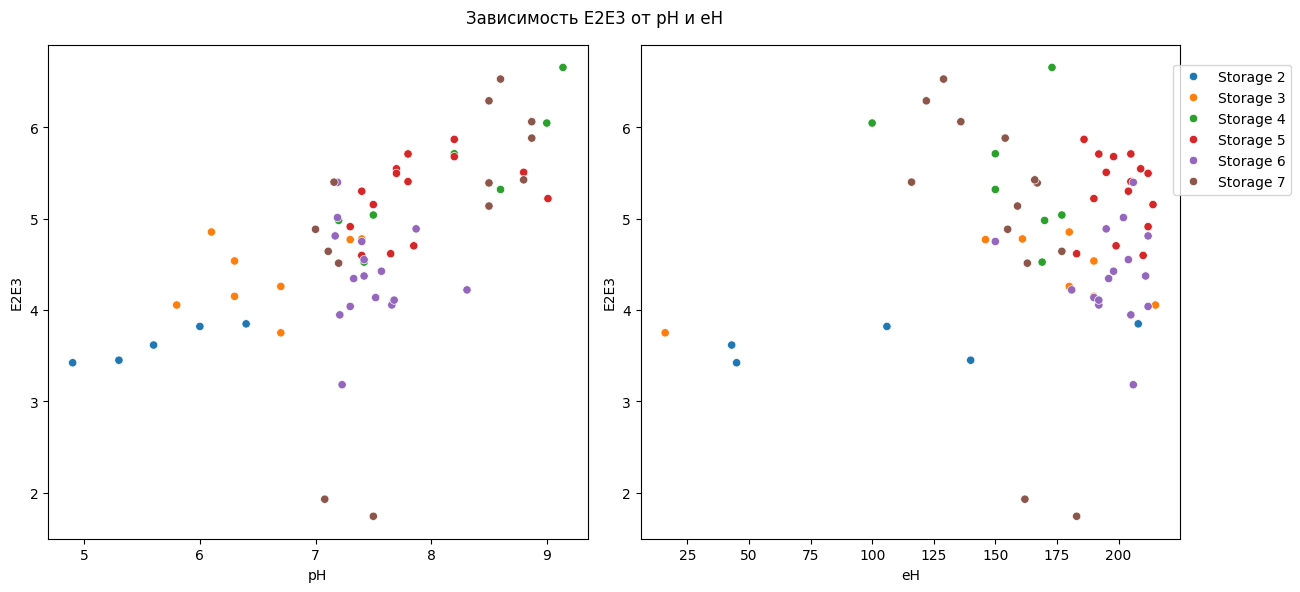

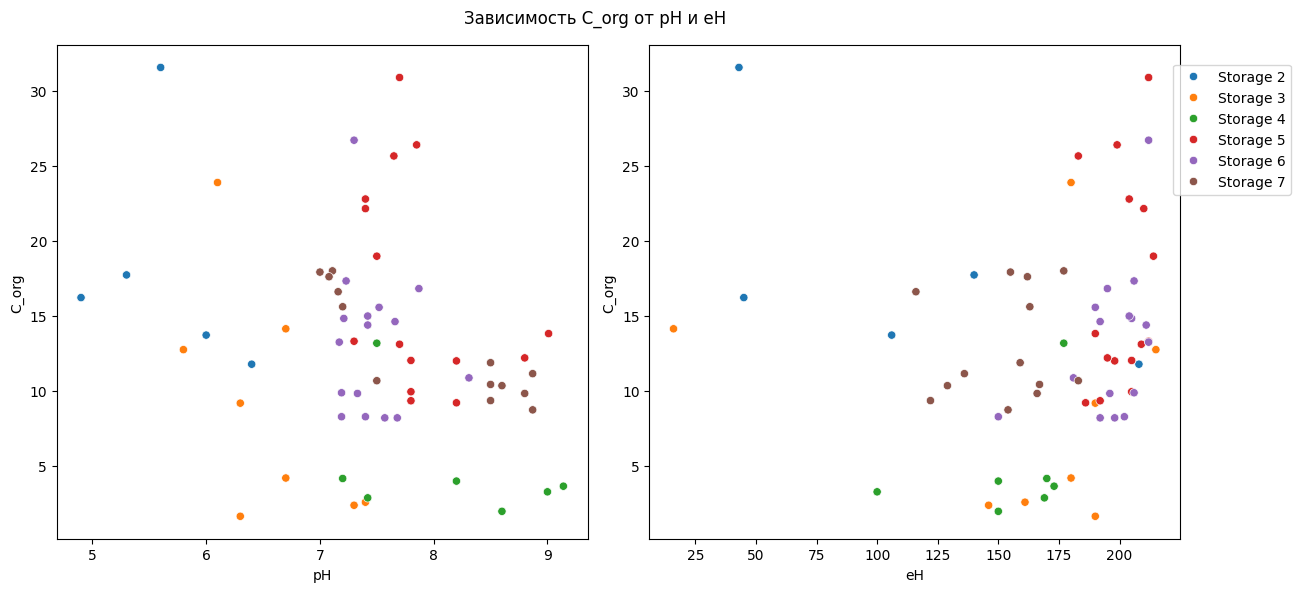

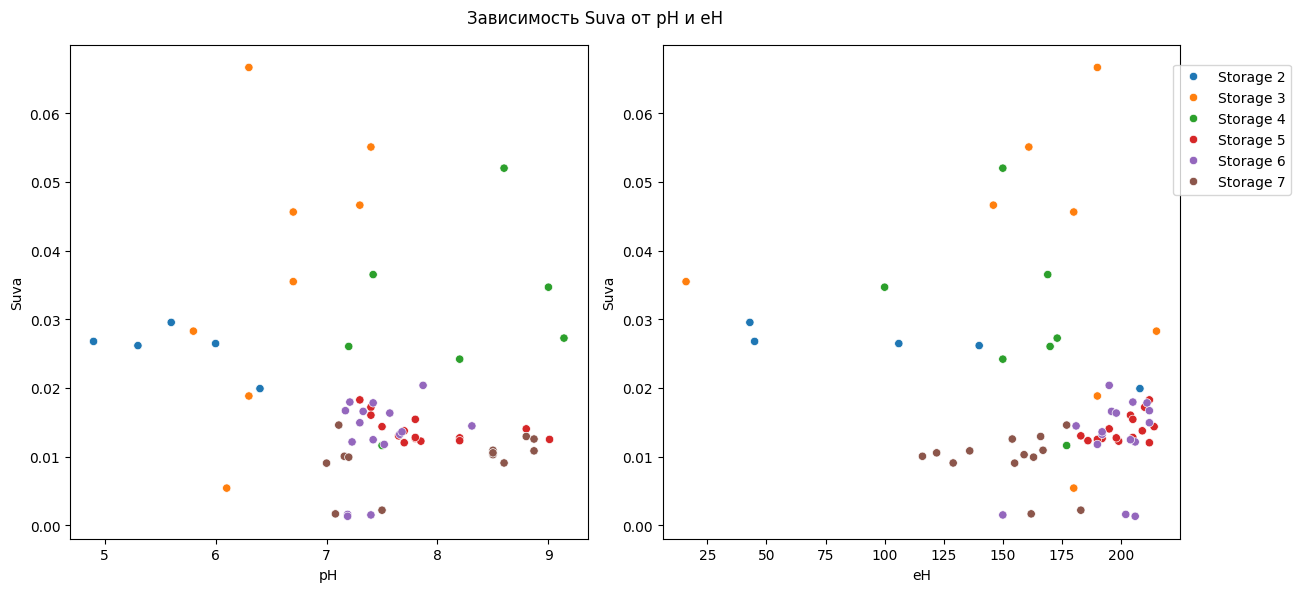

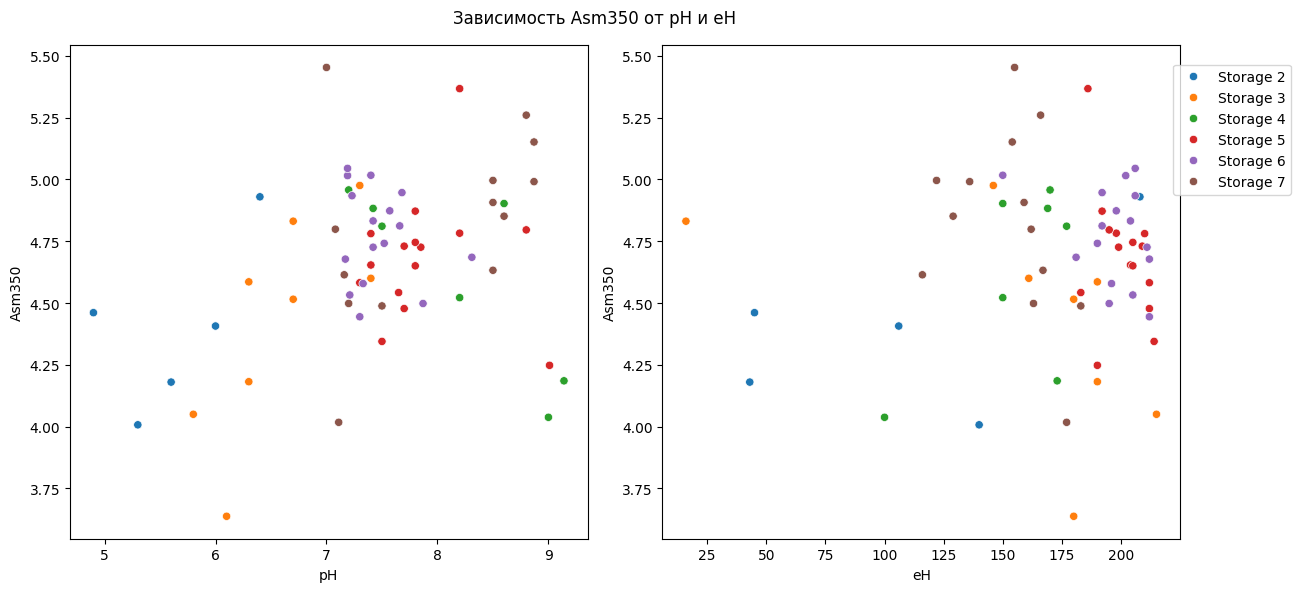

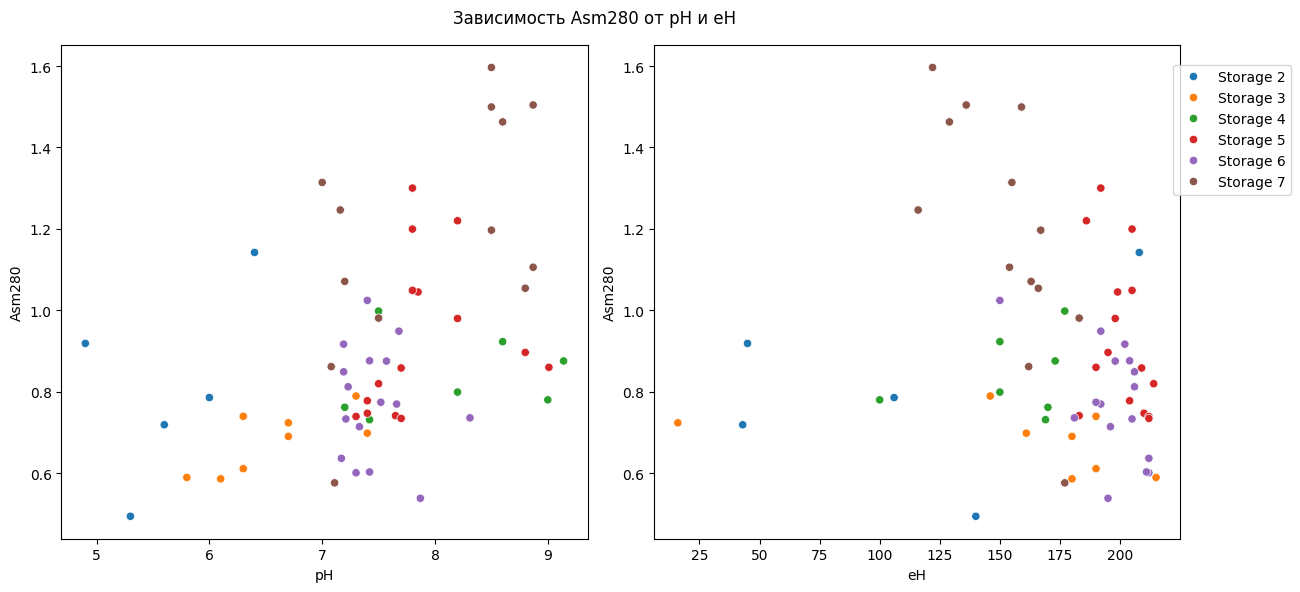

In [23]:
df = MainData

for feature in feature_columns:

    fig, axes = plt.subplots(1,2,figsize=(12,6))

    for i,target in enumerate(target_list):

        sns.scatterplot(data=df.reset_index(), x=target, y=feature, hue="Subclass",ax=axes[i])

    handles, labels = axes[0].get_legend_handles_labels()
    for ax in axes:
        ax.get_legend().remove()
    fig.legend(handles, labels, loc='center left', ncol=1, 
           bbox_to_anchor=(0.976, 0.779))
    
    fig.suptitle(f"Зависимость {feature} от pH и eH")
    plt.savefig(Path.joinpath(wdir_results,"Standart",rf"Зависимость {feature} от pH и eH.png"), bbox_inches='tight', pad_inches=0.1)

    plt.tight_layout()
    plt.show()

In [19]:
def source_clustering(row):

    Subclass = row.name[1]
    

    if Subclass == "Storage 4" or Subclass == "Storage 7" or Subclass == "Storage 1":
        return "Ash"
    
    elif Subclass == "Baikal" or Subclass == "Storage 8":
        return "Outlier"
    
    else:
        return "Lignin"
    
def acid_clustering(row):

    pH = row['pH']

    if pH < 5.7:
        return "Acid"
    
    elif pH > 7.7:
        return "Alkaline"
    
    else:
        return "Neutral"

def oxidation_clustering(row):

    eH = row['eH']

    if eH < 0:
        return "Reduced"
    
    elif eH > 0:
        return "Oxidized"
    
    else:
        return "Neutral"

In [20]:
MainData["Source"] = MainData.apply(lambda x: source_clustering(x), axis=1)
MainData["Acidity"] = MainData.apply(lambda x: acid_clustering(x), axis=1)
MainData["Oxidation"] = MainData.apply(lambda x: oxidation_clustering(x), axis=1)

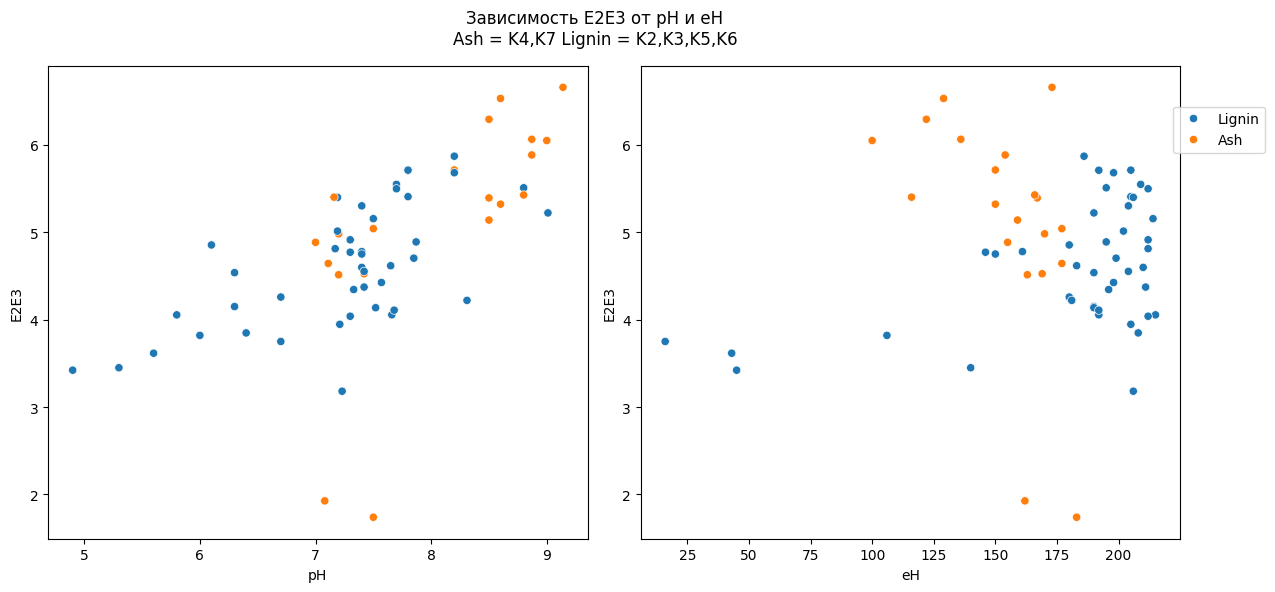

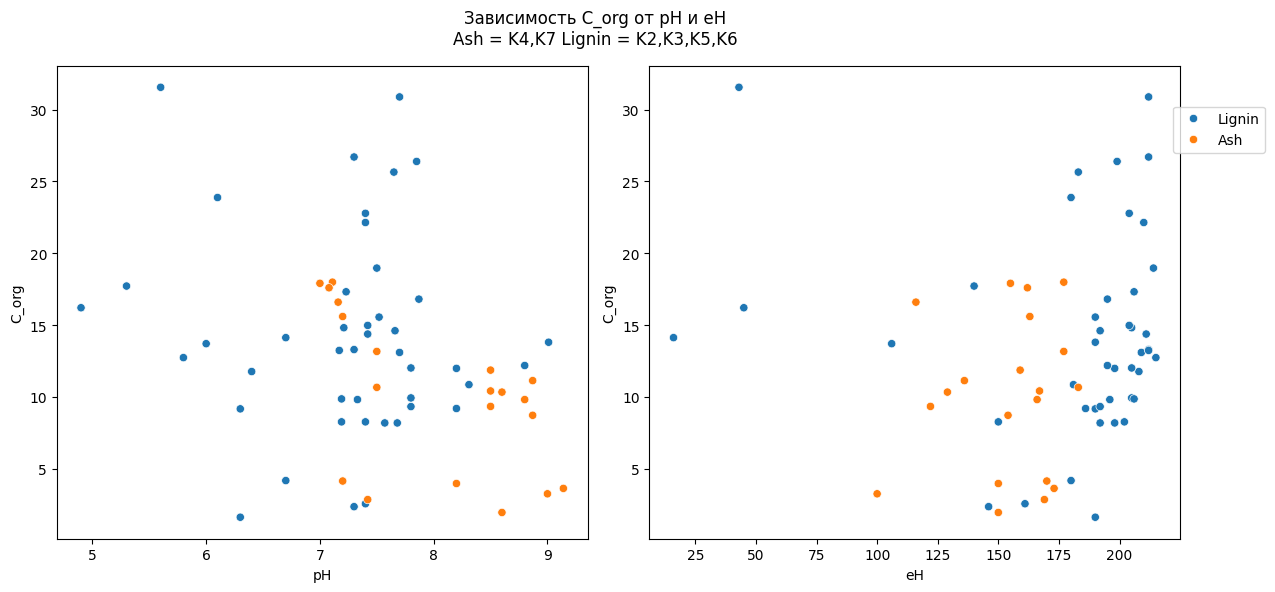

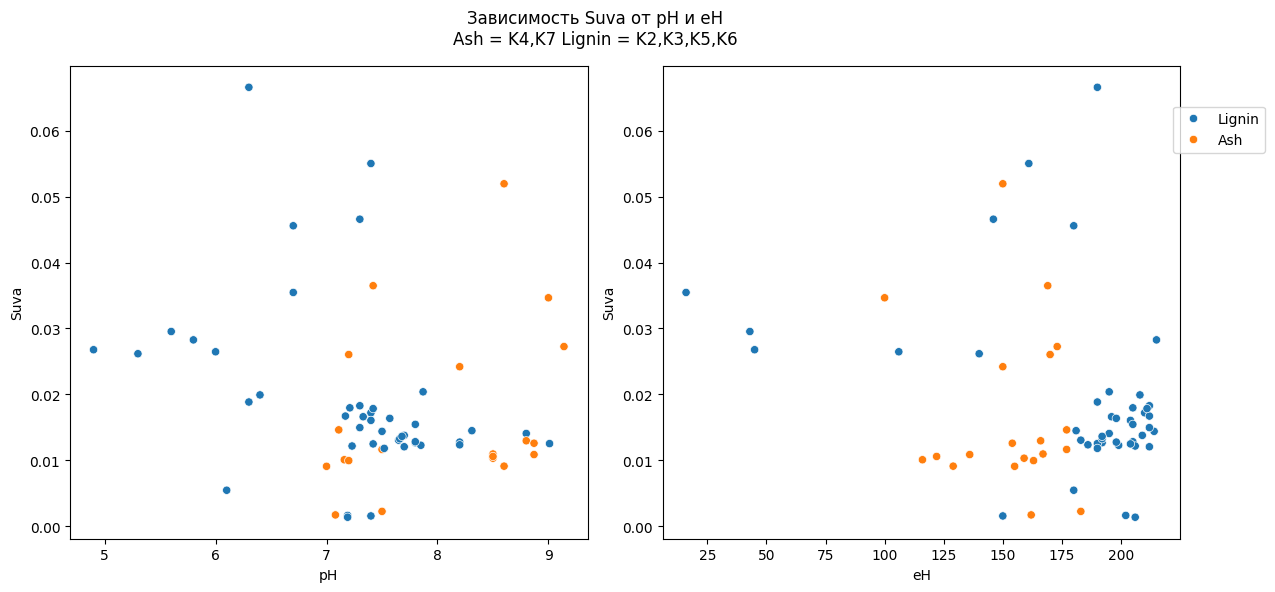

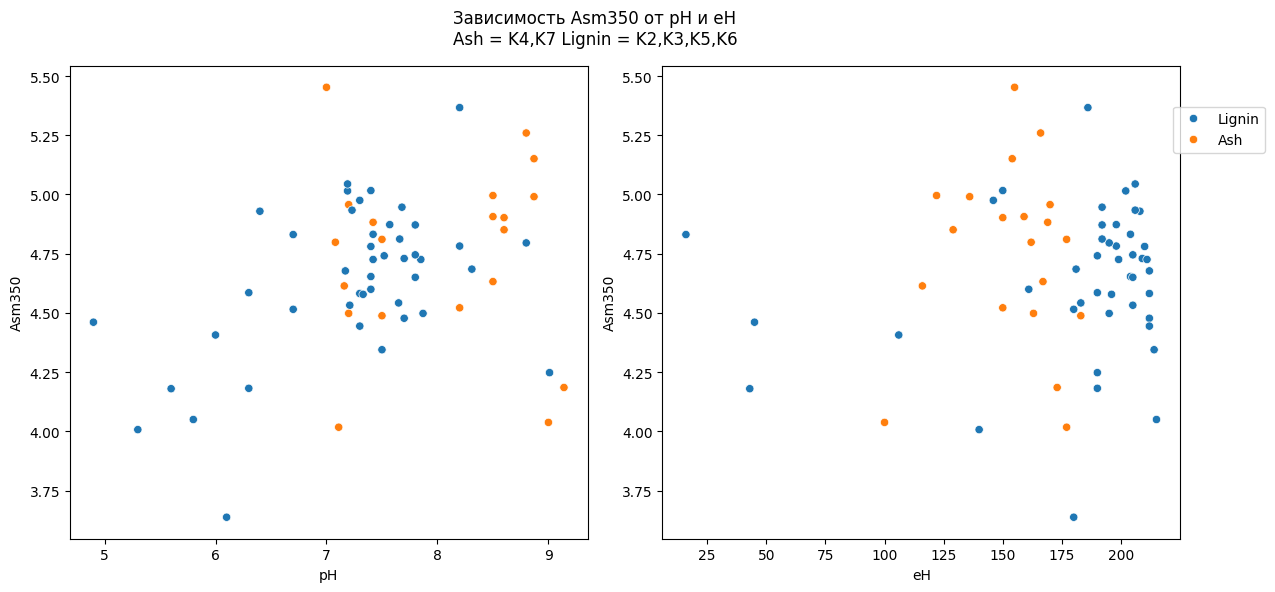

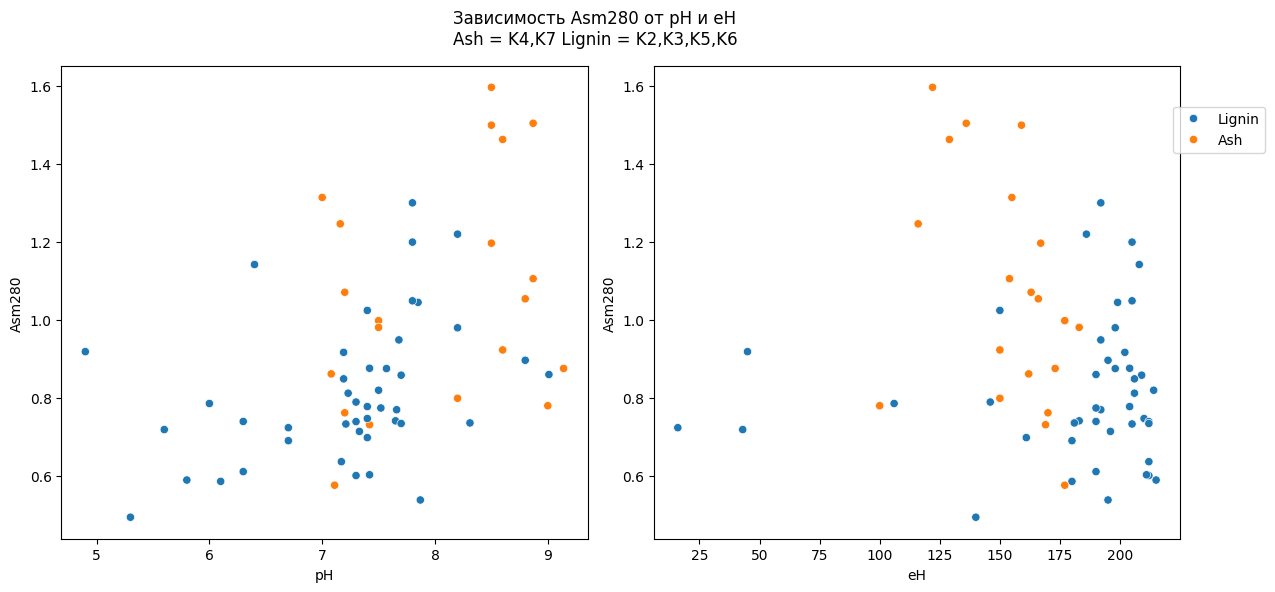

In [24]:
df = MainData

for feature in feature_columns:

    fig, axes = plt.subplots(1,2,figsize=(12,6))

    for i,target in enumerate(target_list):

        sns.scatterplot(data=df.reset_index(), x=target, y=feature, hue="Source",ax=axes[i])

    handles, labels = axes[0].get_legend_handles_labels()
    for ax in axes:
        ax.get_legend().remove()
    fig.legend(handles, labels, loc='center left', ncol=1, 
           bbox_to_anchor=(0.976, 0.779))
    
    fig.suptitle(f"Зависимость {feature} от pH и eH\nAsh = K4,K7 Lignin = K2,K3,K5,K6")

    plt.tight_layout()

    plt.savefig(Path.joinpath(wdir_results,"Source",rf"Зависимость {feature} от pH и eH.png")
                , bbox_inches='tight', pad_inches=0.1)

    plt.show()    

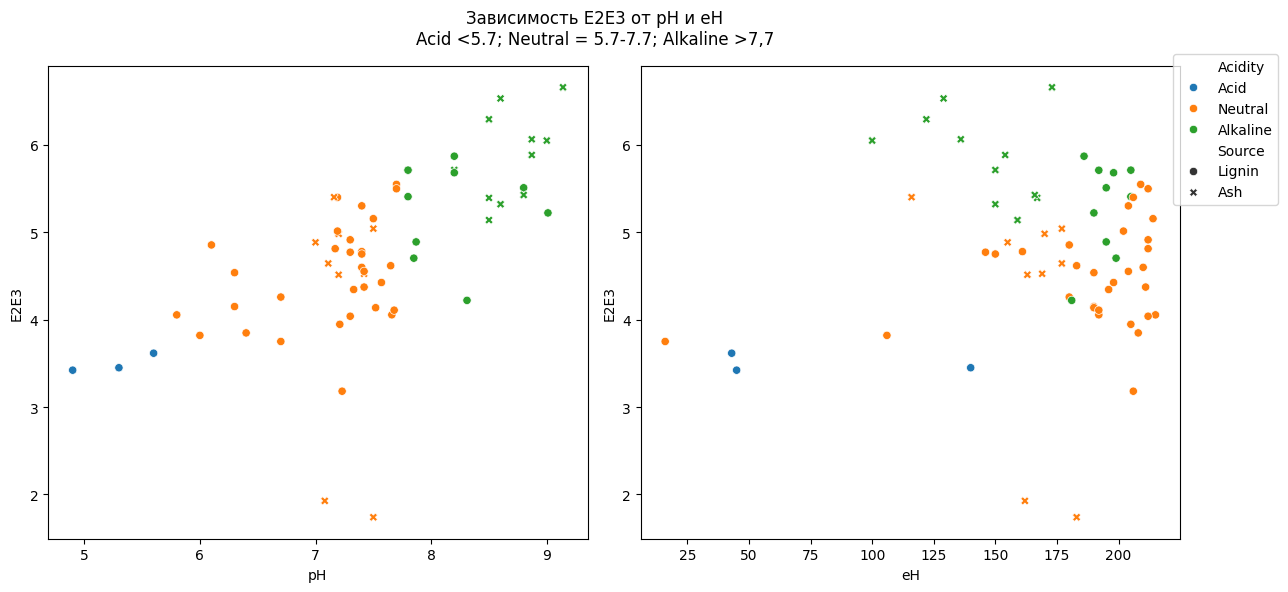

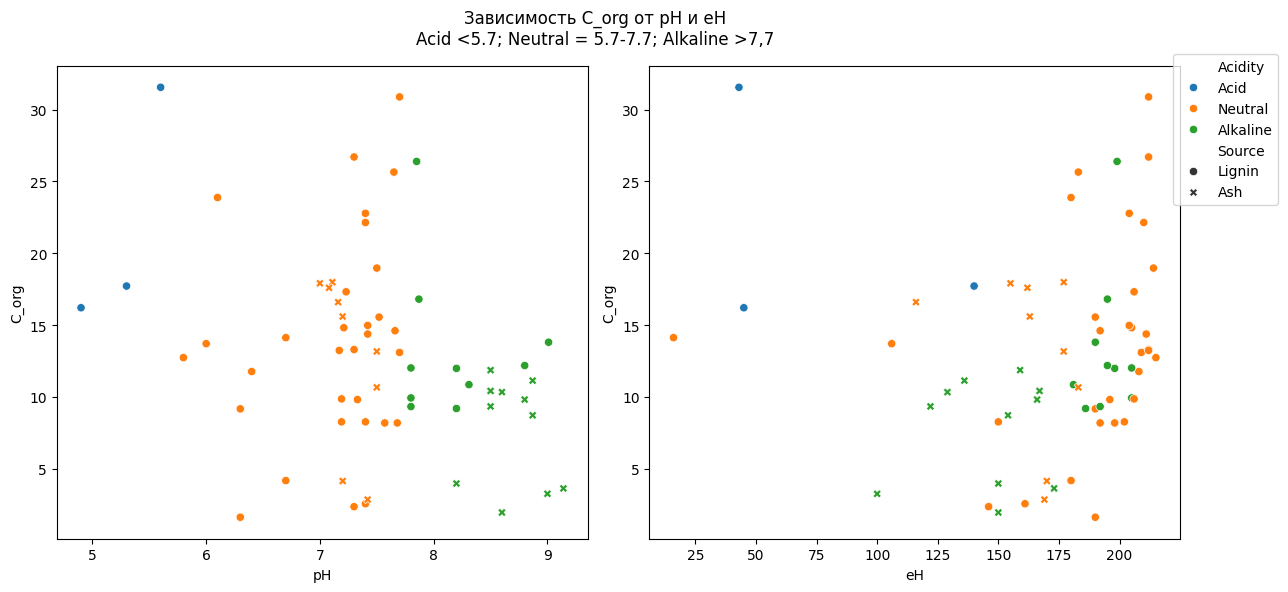

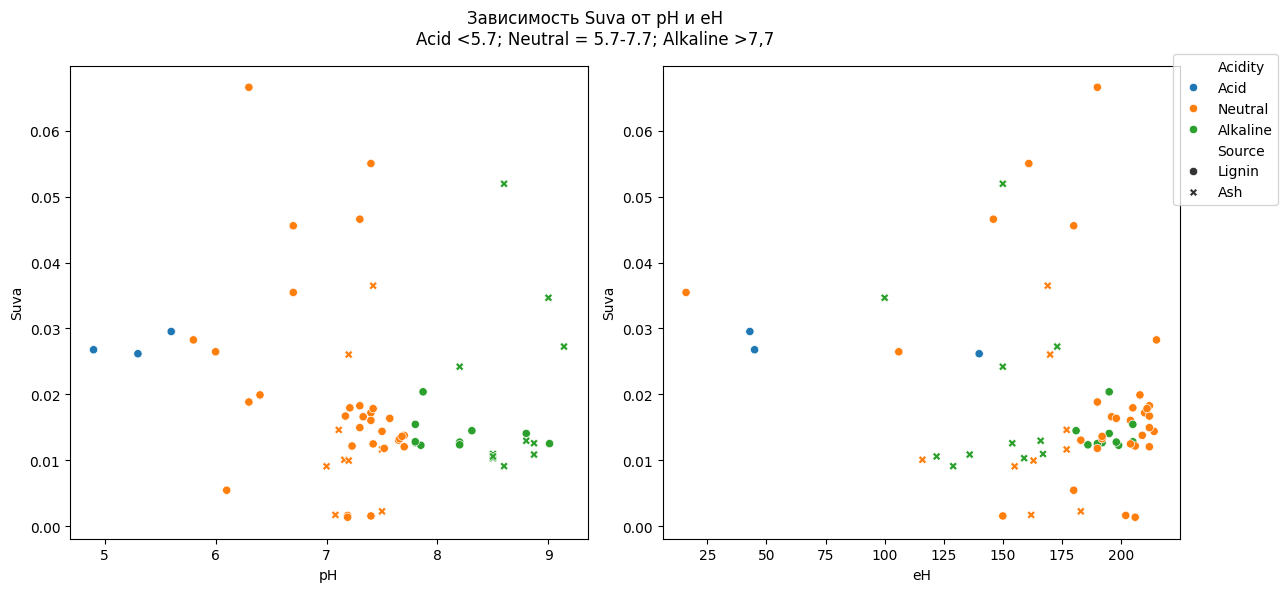

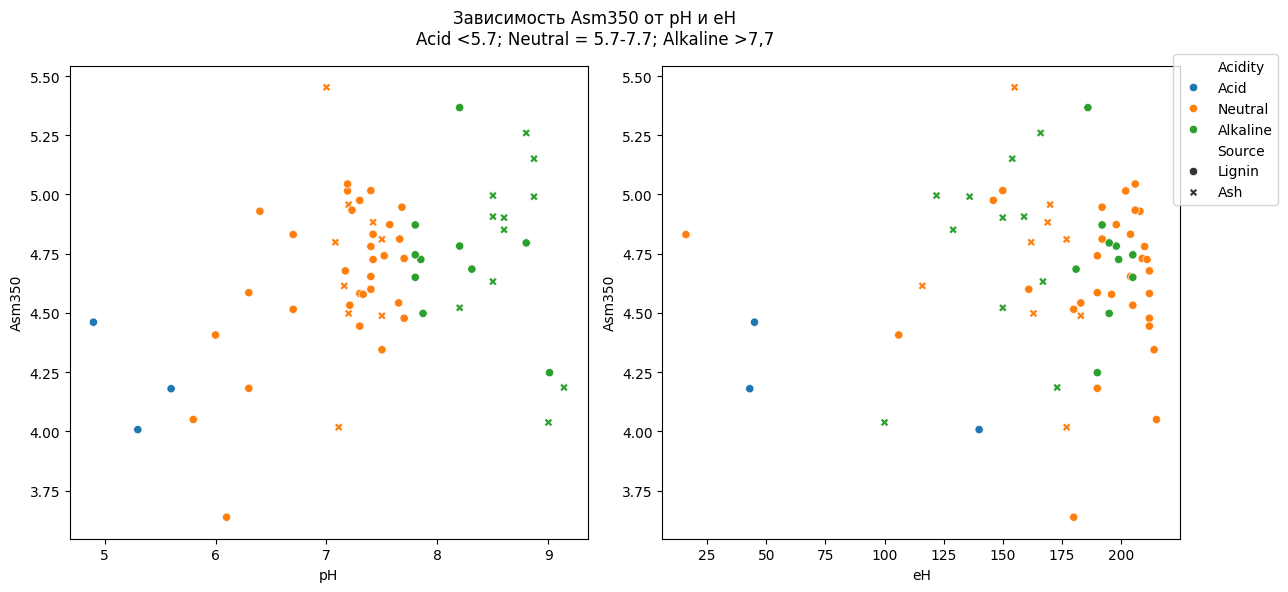

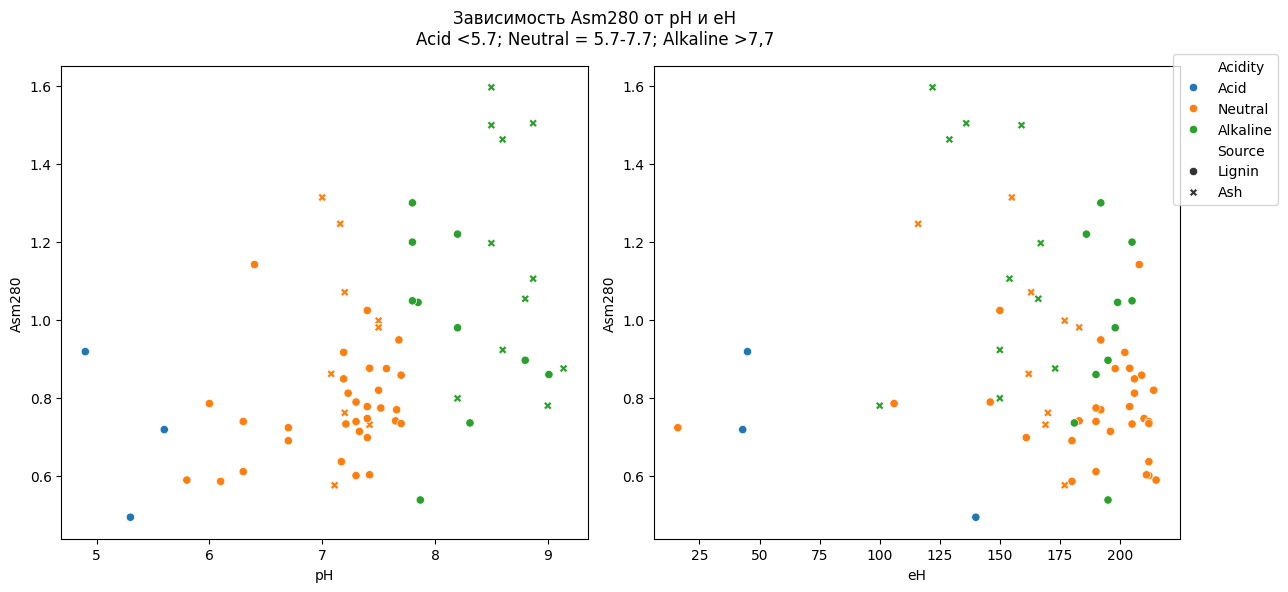

In [25]:
df = MainData

for feature in feature_columns:

    fig, axes = plt.subplots(1,2,figsize=(12,6))

    for i,target in enumerate(target_list):

        sns.scatterplot(data=df.reset_index(), x=target, y=feature, hue="Acidity",ax=axes[i], style="Source")

    handles, labels = axes[0].get_legend_handles_labels()
    for ax in axes:
        ax.get_legend().remove()
    fig.legend(handles, labels, loc='center left', ncol=1, 
           bbox_to_anchor=(0.976, 0.779))
    
    fig.suptitle(f"Зависимость {feature} от pH и eH\nAcid <5.7; Neutral = 5.7-7.7; Alkaline >7,7")

    plt.tight_layout()

    plt.savefig(Path.joinpath(wdir_results,"Acid",rf"Зависимость {feature} от pH и eH.png")
                , bbox_inches='tight', pad_inches=0.1)

    plt.show()